In [2]:
import scanpy as sc
import pandas as pd
import numpy as np
import scrublet as scr
import matplotlib.pyplot as plt
import matplotlib
from matplotlib import rcParams
from matplotlib import rc
from matplotlib import colors
import seaborn as sb
from collections import Counter
import glob

sc.settings.set_figure_params(dpi = 160, color_map = 'RdPu', dpi_save = 300, format = 'pdf')
plt.rcParams["figure.figsize"] = [6,6]
plt.rcParams["pdf.fonttype"] = 42 # add pdf text as one piece instead of letter by letter

In [3]:
import importlib.metadata as md
print(md.version("scrublet"))

0.2.3


In [4]:
print(md.version("scanpy"))

1.11.4


In [5]:
sb.set_palette('colorblind')

In [6]:
# set working directory
%cd /nfs/team205/cs42/HSC/HSC_new_to_transfer/

/nfs/team205/cs42/HSC/HSC_new_to_transfer


In [7]:
# figure directory
fig_path = 'figure/'
sc.settings.figdir = fig_path

# Download dataset

In [8]:
manifest = pd.read_csv('manifest/sample_manifest_23062026_manuscript.csv')
manifest = manifest.loc[manifest['screen_no']=='HOM_1',:]

In [9]:
smp_dict = list(manifest['sequence_name'][~manifest['sequence_name'].isna() ])

In [10]:
smp_dict

['6464STDY14797954', '6464STDY14797955']

In [11]:
# check whether all files have been downloaded in matrix folder - checked - all downloaded from new mapping cellranger 720
DATAFOLDER = '/nfs/team205/cs42/HSC_matrix/'
exist = [x.split('/')[-1] for x in glob.glob(DATAFOLDER + '*')]

missing = [x for x in smp_dict if x not in exist]

if len(missing) > 0:
    print(missing, 'not in matrix folder')

In [12]:
def read_files(filename, raw_file_path = '/nfs/team205/cs42/HSC_matrix/',
               min_n_count = 1000, min_n_gene = 500):

    
    path = '%s/%s/'%(raw_file_path,filename)
    adata = sc.read_10x_h5(path+'filtered_feature_bc_matrix.h5', gex_only=False)
    
    adata.obs_names = [filename+"-"+x.strip("-1") for x in adata.obs_names]
   
    # define mito & GEX
    gex = np.array(adata.var['feature_types']=='Gene Expression')
    mito_genes = np.array(adata.var_names.str.startswith('MT-')) & gex
    exog_genes = np.array(adata.var_names.str.startswith('EXOG_')) 
    # update gex to exclude exog_genes
    gex_update = gex & ~exog_genes
    
    antibody_capture = np.array(adata.var['feature_types']=='Antibody Capture')
    
    # caculate n_counts / n_genes per cell
    adata.obs['n_counts_GEX'] = np.sum(adata[:,gex_update].X, axis=1).A1
    adata.obs['n_genes'] = np.sum(adata[:,gex_update].X>0,axis=1)
    adata.obs['n_counts_antibody_capture'] = np.sum(adata[:,antibody_capture].X, axis=1).A1
    
    # calculate mito%
    adata.obs['mito'] = (np.sum(adata.X[:, mito_genes],axis=1).A1) / (np.sum(adata[:,gex_update].X,axis=1).A1)
    
    
    # filter cells
    clist = []
    clist.append(np.array(adata.obs['n_counts_GEX'] > 1000))
    clist.append(np.array(adata.obs['n_genes'] > 500))
    #clist.append(np.array(adata.obs['n_genes'] < 7000))
    clist.append(np.array(adata.obs['mito'] < 0.2)) # filter out mito >= 0.2
    
    c = np.column_stack(clist).all(axis=1)
    adata = adata[c].copy()
    
    # update manifest onto .obs
    adata.obs['file'] = filename
    adata.obs['sanger_sample_ID'] = manifest.loc[manifest['sequence_name']==filename, 'sanger_sample_ID'].item()
    adata.obs['screen_no'] = manifest.loc[manifest['sequence_name']==filename, 'screen_no'].item()
    adata.obs['HSC_days'] = manifest.loc[manifest['sequence_name']==filename, 'HSC days'].item()
    adata.obs['FACS_sort'] = manifest.loc[manifest['sequence_name']==filename, 'FACS_sort'].item()
    adata.obs['10x_kit'] = manifest.loc[manifest['sequence_name']==filename, '10x kit'].item()
    
    # calculate doublets using scrublet
    scrub = scr.Scrublet(adata.X)
    doublet_scores, predicted_doublets = scrub.scrub_doublets(verbose=False)
    adata.obs['doublet_scores'] = doublet_scores
    adata.obs['predicted_doublets'] = predicted_doublets
    
    sc.write('%s_filtered'%(filename),adata)

In [13]:
from multiprocessing import Pool

with Pool(10) as p:
    p.map(read_files, [x for x in smp_dict])

/nfs/users/nfs_c/cs42/.conda/envs/myclone/lib/python3.11/site-packages/anndata/_core/anndata.py:1776: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/nfs/users/nfs_c/cs42/.conda/envs/myclone/lib/python3.11/site-packages/anndata/_core/anndata.py:1776: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/nfs/users/nfs_c/cs42/.conda/envs/myclone/lib/python3.11/site-packages/anndata/_core/anndata.py:1776: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/nfs/users/nfs_c/cs42/.conda/envs/myclone/lib/python3.11/site-packages/anndata/_core/anndata.py:1776: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


# Merge dataset

In [14]:
ad = {}

In [15]:
for filename in smp_dict:
    ad[filename] = sc.read('%s_filtered'%(filename))
    ad[filename].var_names_make_unique()

/nfs/users/nfs_c/cs42/.conda/envs/myclone/lib/python3.11/site-packages/anndata/_core/anndata.py:1776: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/nfs/users/nfs_c/cs42/.conda/envs/myclone/lib/python3.11/site-packages/anndata/_core/anndata.py:1776: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


In [16]:
merged = None;
for key in ad: 
    if merged is None:
        merged = ad[key]
    else:
        merged = merged.concatenate(ad[key], join='outer')

/tmp/ipykernel_3183140/1590458944.py:6: FutureWarning: Use anndata.concat instead of AnnData.concatenate, AnnData.concatenate is deprecated and will be removed in the future. See the tutorial for concat at: https://anndata.readthedocs.io/en/latest/concatenation.html
  merged = merged.concatenate(ad[key], join='outer')


In [17]:
Counter(merged.obs['file'])

Counter({'6464STDY14797955': 8314, '6464STDY14797954': 2288})

### Remove doublets

In [18]:
merged = merged[merged.obs['doublet_scores']<0.4]
merged = merged[merged.obs['predicted_doublets']==False]

In [19]:
Counter(merged.obs['file'])

Counter({'6464STDY14797955': 8231, '6464STDY14797954': 2222})

# Call exog_TF

In [20]:
exog_genes = merged.var_names[merged.var_names.str.startswith('EXOG_')]

In [21]:
print(exog_genes)

Index(['EXOG_EGFP', 'EXOG_PuroR', 'EXOG_Bxb1', 'EXOG_Bsd', 'EXOG_mApple',
       'EXOG_GFI1B', 'EXOG_GFI1', 'EXOG_HLF', 'EXOG_IKZF1', 'EXOG_IRF5',
       'EXOG_MYB_CON', 'EXOG_MYCN', 'EXOG_NFE2', 'EXOG_RUNX1',
       'EXOG_SP100variant1', 'EXOG_SPI1', 'EXOG_TFEC', 'EXOG_BCL11Avariant1'],
      dtype='object')


## Exog_TF calling

In [22]:
exog_exception = ['EXOG_mApple','EXOG_Bsd', 'EXOG_Bxb1','EXOG_PuroR']
exog_genes_count = [gene for gene in exog_genes if gene not in exog_exception]

Threshold of 1 selected from hOM_LINE.A01.v01.load_data_empty_droplet.ipynb

In [25]:
from scipy import sparse

# Get sparse cell x barcode matrix
X = merged[:, exog_genes_count].X.tocsr(copy=True)

# Set all counts of 1 to 0
X.data[X.data == 1] = 0
X.eliminate_zeros()

barcode_names = np.array(exog_genes_count)

top1_barcode = []
top1_count = []
top2_barcode = []
top2_count = []

for i in range(X.shape[0]):
    start, end = X.indptr[i], X.indptr[i + 1]

    counts = X.data[start:end]
    cols = X.indices[start:end]

    if counts.size == 0:
        top1_barcode.append(np.nan)
        top1_count.append(0)
        top2_barcode.append(np.nan)
        top2_count.append(0)

    elif counts.size == 1:
        top1_barcode.append(barcode_names[cols[0]])
        top1_count.append(counts[0])
        top2_barcode.append(np.nan)
        top2_count.append(0)

    else:
        order = np.argsort(counts)[::-1]

        top1_idx = order[0]
        top2_idx = order[1]

        top1_barcode.append(barcode_names[cols[top1_idx]])
        top1_count.append(counts[top1_idx])

        top2_barcode.append(barcode_names[cols[top2_idx]])
        top2_count.append(counts[top2_idx])

top2_df = pd.DataFrame(
    {
        "top1_barcode": top1_barcode,
        "top1_count": top1_count,
        "top2_barcode": top2_barcode,
        "top2_count": top2_count,
    },
    index=merged.obs_names
)

top2_df["n_called_barcodes"] = (
    top2_df[["top1_barcode", "top2_barcode"]]
    .notna()
    .sum(axis=1)
)

In [26]:
merged.obs[["top1_barcode", "top1_count", "top2_barcode", "top2_count","n_called_barcodes"]] = top2_df

/tmp/ipykernel_3183140/202986937.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sb.barplot(


Text(0, 0.5, 'number of cells')

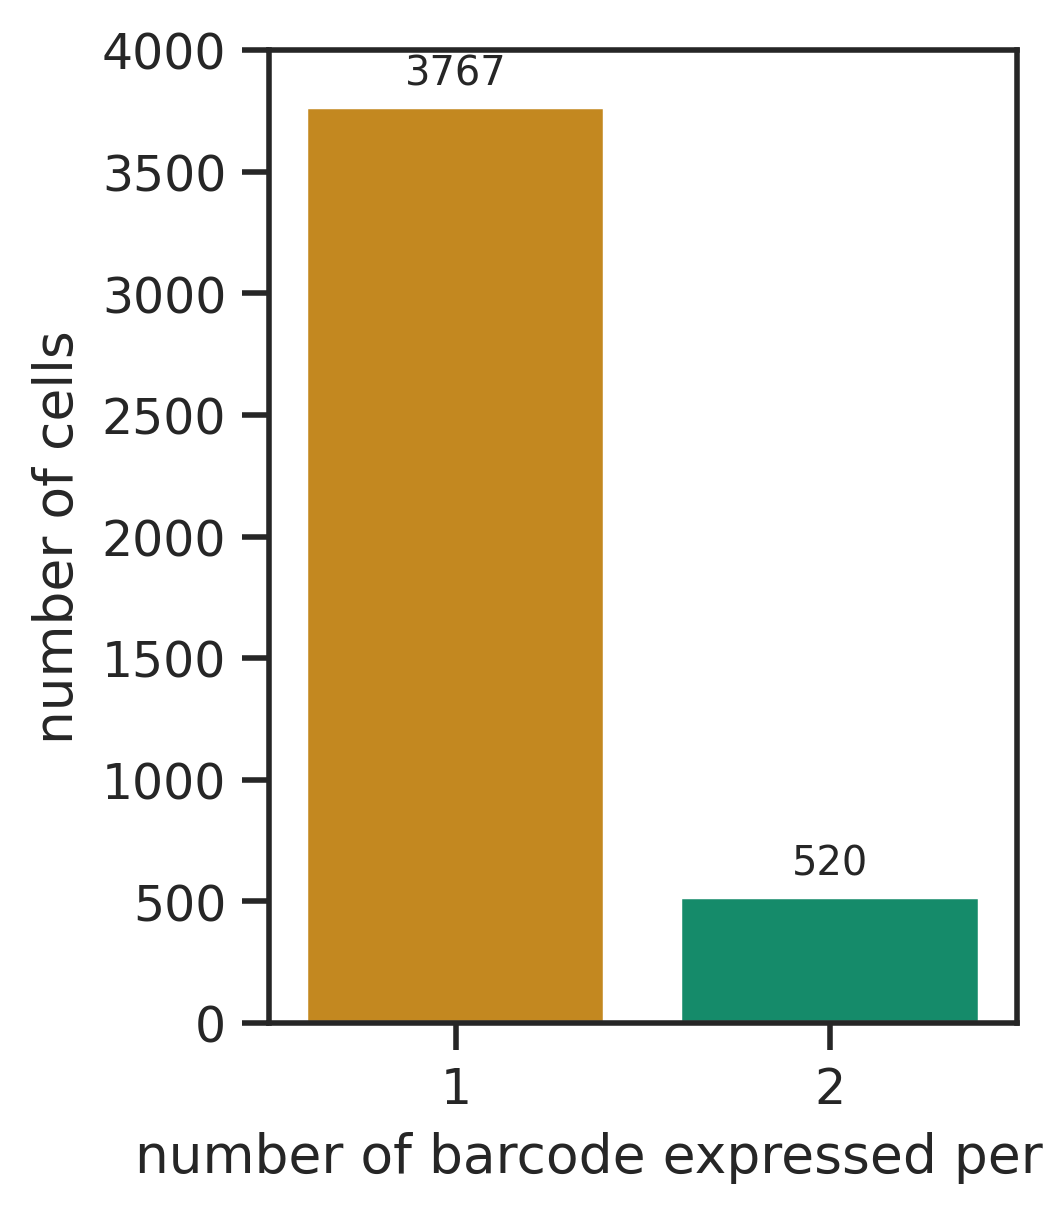

In [38]:
# seaborn theme
sb.set_theme(style="ticks")

# count cells per barcode number
df = (
    pd.Series(top2_df["n_called_barcodes"]).value_counts()
      .sort_index()
      .reset_index()
)
df.columns = ["n_called_barcodes", "n_cell"]

# plot
plt.figure(figsize=(3, 4))
ax = sb.barplot(
    data=df,
    x="n_called_barcodes",
    y="n_cell",
    palette="colorblind"   # different color for each bar
)


# add counts on top of bars
for p in ax.patches:
    height = p.get_height()
    ax.annotate(
        f"{int(height)}",
        (p.get_x() + p.get_width() / 2., height),
        ha="center",
        va="bottom",
        fontsize=9,
        xytext=(0, 3),
        textcoords="offset points"
    )

# axis formatting
ax.set_xlim(0.5,2.5)  
ax.set_ylim(0,4000)
ax.set_xlabel("number of barcode expressed per cell")
ax.set_ylabel("number of cells")

#plt.savefig(fig_path+"HOM_screen_cell_barcode_histogram.pdf", bbox_inches='tight')

Now remove the exogenous genes from adata.var before log-normalisation 

In [39]:
# only leave GEX genes for downstream
merged = merged[:,~merged.var_names.isin(exog_genes)]

In [40]:
merged = merged.copy()

In [41]:
merged.write_h5ad('write/hom_screen_entire_data_raw_count.h5ad')

## Preprocessing - normalise and log

In [476]:
merged = sc.read('write/hom_screen_entire_data_raw_count.h5ad')

Only considering the two last: ['.entire_data_raw_count', '.h5ad'].
Only considering the two last: ['.entire_data_raw_count', '.h5ad'].


In [42]:
sc.pp.normalize_per_cell(merged,counts_per_cell_after=1e4,key_n_counts='n_counts_GEX')

/tmp/ipykernel_3183140/1240904363.py:1: FutureWarning: Use sc.pp.normalize_total instead
  sc.pp.normalize_per_cell(merged,counts_per_cell_after=1e4,key_n_counts='n_counts_GEX')
/nfs/users/nfs_c/cs42/.conda/envs/myclone/lib/python3.11/site-packages/scanpy/preprocessing/_simple.py:591: FutureWarning: Use sc.pp.normalize_total instead
  normalize_per_cell(


In [43]:
sc.pp.log1p(merged)

In [44]:
merged.write_h5ad('write/hom_screen_entire_data_normalised_log.h5ad')